# Лабораторная работа 2. Word2vec, PMI и геометрия эмбеддингов (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и представления слов

**Цель.** Реализовать skip-gram with negative sampling (SGNS) с ручным выводом градиентов и экспериментально проверить, что SGNS неявно факторизует сдвинутую матрицу PMI (Levy & Goldberg, 2014).

**Что нужно сдать:**
1. SGNS с ручными градиентами, прошедший проверку градиентов (autograd и конечные разности).
2. Эмбеддинги SVD(PPMI).
3. Сравнение двух моделей на SimLex-999, MEN и аналогиях.
4. Численную проверку теоремы Леви–Голдберга.
5. Анализ анизотропии пространства и эффекта центрирования.

**Теория.** Для пары «центральное слово \(w\) — контекст \(c\)» с \(k\) негативными примерами \(c_N \sim P_n\):
\[
\ell(w, c) = -\log\sigma(\mathbf{w}^\top \mathbf{c}) - \sum_{n=1}^{k}\log\sigma(-\mathbf{w}^\top \mathbf{c}_{N_n}).
\]
Если размерность эмбеддингов достаточна, чтобы каждое произведение \(x = \mathbf{w}^\top\mathbf{c}\) оптимизировалось независимо, оптимум ожидаемой функции потерь достигается при
\[
\mathbf{w}^\top \mathbf{c} = \log\frac{\#(w,c)}{\#(w)\, P_n(c)} - \log k ,
\]
то есть при сдвинутой (на \(\log k\)) PMI относительно распределения негативов.

In [ ]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Корпус text8 и словарь

In [ ]:
import zipfile
from collections import Counter

zpath = download("http://mattmahoney.net/dc/text8.zip", "text8.zip")
with zipfile.ZipFile(zpath) as z:
    raw = z.read("text8").decode("utf-8")
N_CHARS = 10_000_000 if FAST_DEV_RUN else 100_000_000
tokens = raw[:N_CHARS].split()
MIN_COUNT, MAX_VOCAB = 5, (10_000 if FAST_DEV_RUN else 50_000)
freq = Counter(tokens)
itos = [w for w, c in freq.most_common(MAX_VOCAB) if c >= MIN_COUNT]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
corpus = np.array([stoi[t] for t in tokens if t in stoi], dtype=np.int64)
counts = np.bincount(corpus, minlength=V).astype(np.float64)
print(f"токенов: {len(corpus):,}, словарь: {V:,}")

токенов: 1,552,964, словарь: 10,000


In [ ]:
tokens[:10]

['anarchism',
 'originated',
 'as',
 'a',
 'term',
 'of',
 'abuse',
 'first',
 'used',
 'against']

In [ ]:
corpus[:10]

array([1162, 2957,   12,    6,  190,    1, 4317,   46,   59,  138])

In [ ]:
counts

array([1.07002e+05, 6.16160e+04, 4.57900e+04, ..., 1.30000e+01,
       1.30000e+01, 1.30000e+01])

## 1. Обучающие пары и распределение негативов

- Окно фиксированной ширины `WINDOW` (без динамического сужения, чтобы проверка теоремы была точной).
- Распределение негативов \(P_n(c) \propto \#(c)^{0.75}\).
- Subsampling частых слов можно включить для основного эксперимента, но для проверки теоремы его нужно отключить: теорема говорит о тех парах, на которых реально идёт обучение.

In [ ]:
WINDOW, K_NEG, DIM = 4, 5, 100

def make_pairs(corpus, window):
    """Все пары (центр, контекст) на расстоянии 1..window в обе стороны."""
    centers_list, contexts_list = [], []
    n = len(corpus)
    for d in range(1, window + 1):
        # контекст справа: позиции 0..n-d-1
        centers_list.append(corpus[:n - d])
        contexts_list.append(corpus[d:])
        # контекст слева: позиции d..n-1
        centers_list.append(corpus[d:])
        contexts_list.append(corpus[:n - d])
    centers = np.concatenate(centers_list)
    contexts = np.concatenate(contexts_list)
    return centers, contexts

centers, contexts = make_pairs(corpus, WINDOW)
neg_probs = counts ** 0.75
neg_probs /= neg_probs.sum()
print(f"пар: {len(centers):,}")

пар: 12,423,692


## 2. Градиенты SGNS

Обозначим $s_+ = \sigma(\mathbf{w}^\top\mathbf{c}_+)$ и $s_n = \sigma(\mathbf{w}^\top\mathbf{c}_{N_n})$.

Выведите и реализуйте:

$$ \frac{\partial \ell}{\partial \mathbf{w}} = (s_+ - 1)\,\mathbf{c}_+ + \sum_n s_n \mathbf{c}_{N_n} $$

$$ \frac{\partial \ell}{\partial \mathbf{c}_+} = (s_+ - 1)\,\mathbf{w} $$

$$ \frac{\partial \ell}{\partial \mathbf{c}_{N_n}} = s_n\,\mathbf{w} $$

Функция работает с батчем и **не использует autograd**.


In [ ]:
def sgns_loss_and_grads(w, c, n):
    """w, c: (B, d); n: (B, k, d). Возвращает сумму потерь и градиенты по w, c, n."""
    sp_ = torch.sigmoid((w * c).sum(-1))                     # sigma(w.c), (B,)
    sn_ = torch.sigmoid(torch.einsum("bd,bkd->bk", w, n))    # sigma(w.n_i), (B, k)
    loss = -(torch.log(sp_) + torch.log(1 - sn_).sum(-1)).sum()
    gw = (sp_ - 1)[:, None] * c + torch.einsum("bk,bkd->bd", sn_, n)
    gc = (sp_ - 1)[:, None] * w
    gn = sn_[..., None] * w[:, None, :]
    return loss, gw, gc, gn

### Проверка градиентов

1. Сравните с autograd на случайном батче (в `float64`).
2. Выполните проверку конечными разностями по нескольким случайным координатам: $(\frac{\ell(\theta + \varepsilon e_i) - \ell(\theta - \varepsilon e_i)}{2\varepsilon}).$

In [ ]:
torch.manual_seed(0)
B, d, k = 7, 5, 3
Wb = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cp = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cn = torch.randn(B, k, d, dtype=torch.float64, requires_grad=True)
loss, gW, gCp, gCn = sgns_loss_and_grads(Wb.detach(), Cp.detach(), Cn.detach())
ref = -(F.logsigmoid((Wb * Cp).sum(-1)) + F.logsigmoid(-torch.einsum("bd,bkd->bk", Wb, Cn)).sum(-1)).sum()
ref.backward()
for name, a, b in [("W", gW, Wb.grad), ("Cpos", gCp, Cp.grad), ("Cneg", gCn, Cn.grad)]:
    print(name, "max |diff| =", (a - b).abs().max().item())
    assert torch.allclose(a, b, atol=1e-10)

eps = 1e-6
B, d = Wb.shape
g = torch.Generator().manual_seed(123)

# фиксированные копии Cp, Cn — они не меняются
Cp0 = Cp.detach()
Cn0 = Cn.detach()

max_err = 0.0
for trial in range(10):
    b = int(torch.randint(0, B, (1,), generator=g))
    j = int(torch.randint(0, d, (1,), generator=g))

    Wp = Wb.detach().clone()
    Wm = Wb.detach().clone()
    Wp[b, j] += eps
    Wm[b, j] -= eps

    with torch.no_grad():
        lp = sgns_loss_and_grads(Wp, Cp0, Cn0)[0].item()
        lm = sgns_loss_and_grads(Wm, Cp0, Cn0)[0].item()

    fd   = (lp - lm) / (2 * eps)      # конечная разность
    anal = gW[b, j].item()            # ручной градиент
    err  = abs(fd - anal)
    max_err = max(max_err, err)
    print(f"Wb[{b},{j}]: FD={fd:+.8f}  manual={anal:+.8f}  |diff|={err:.2e}")

print(f"\nmax |FD - manual| = {max_err:.2e}")
assert max_err < 1e-6, f"конечные разности расходятся: {max_err:.2e}"

W max |diff| = 4.440892098500626e-16
Cpos max |diff| = 1.6653345369377348e-16
Cneg max |diff| = 2.220446049250313e-16
Wb[2,4]: FD=+0.05445210  manual=+0.05445210  |diff|=8.10e-10
Wb[0,0]: FD=-0.01666962  manual=-0.01666962  |diff|=7.86e-10
Wb[3,2]: FD=-2.36629144  manual=-2.36629145  |diff|=1.35e-09
Wb[2,2]: FD=+0.75988256  manual=+0.75988256  |diff|=7.73e-10
Wb[5,4]: FD=-2.33343504  manual=-2.33343504  |diff|=1.46e-09
Wb[5,1]: FD=-0.44596852  manual=-0.44596852  |diff|=5.87e-10
Wb[3,1]: FD=-0.05188556  manual=-0.05188557  |diff|=1.62e-09
Wb[6,4]: FD=+0.94865077  manual=+0.94865077  |diff|=1.84e-09
Wb[4,1]: FD=-0.25790451  manual=-0.25790452  |diff|=1.41e-09
Wb[2,0]: FD=-1.26974814  manual=-1.26974814  |diff|=9.64e-10

max |FD - manual| = 1.84e-09


Выводы:

Autograd-проверка и конечные разности дали расхождение близкое к нулю, значит градиенты реализованы корректно.

## 3. Обучение SGNS

Используйте разреженное обновление SGD: в батче обновляются только строки, встретившиеся в нём (`index_add_`). Learning rate линейно убывает до нуля, как в оригинальном word2vec.

обучение: 82 c


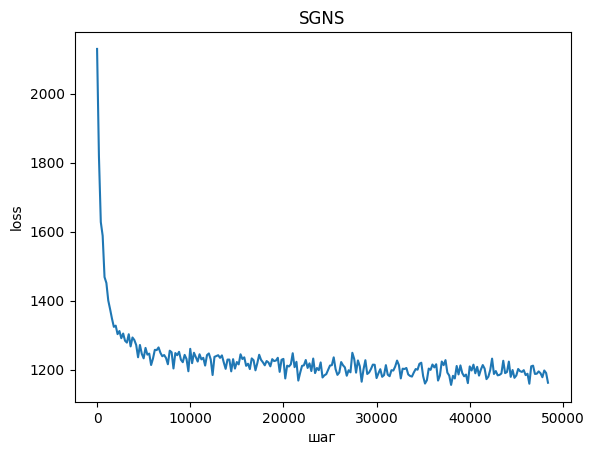

In [ ]:
def train_sgns(centers, contexts, V, dim=DIM, k=K_NEG, epochs=1, batch=512, lr0=0.025, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    W = (torch.rand(V, dim, generator=g) - 0.5) / dim
    C = torch.zeros(V, dim)
    neg_t = torch.tensor(neg_probs, dtype=torch.float)
    n = len(centers); steps = epochs * (n // batch); step = 0; hist = []
    cen_t, ctx_t = torch.from_numpy(centers), torch.from_numpy(contexts)
    for ep in range(epochs):
        perm = torch.randperm(n, generator=g)
        for b in range(n // batch):
            idx = perm[b * batch:(b + 1) * batch]
            wi, ci = cen_t[idx], ctx_t[idx]
            ni = torch.multinomial(neg_t, batch * k, replacement=True, generator=g).view(batch, k)
            lr = lr0 * max(1e-4, 1 - step / steps)

            # достаём эмбеддинги
            Wb = W[wi]              # (batch, dim)
            Cpos = C[ci]            # (batch, dim)
            Cneg = C[ni]            # (batch, k, dim)

            # loss и ручные градиенты
            loss, gW, gCpos, gCneg = sgns_loss_and_grads(Wb, Cpos, Cneg)

            # разреженное обновление только встретившиеся строки
            with torch.no_grad():
                W.index_add_(0, wi, -lr * gW)
                C.index_add_(0, ci, -lr * gCpos)
                C.index_add_(0, ni.reshape(-1), -lr * gCneg.reshape(-1, dim))

            if step % 200 == 0: hist.append((step, loss.item()))
            step += 1
    return W, C, hist

t0 = time.time()
W_sgns, C_sgns, hist = train_sgns(centers, contexts, V, epochs=2 if FAST_DEV_RUN else 5)
print(f"обучение: {time.time() - t0:.0f} c")
plt.plot(*zip(*hist)); plt.xlabel("шаг"); plt.ylabel("loss"); plt.title("SGNS"); plt.show()

## 4. PPMI и SVD

1. Постройте разреженную матрицу совместной встречаемости \(\#(w,c)\) по тем же парам.
2. Вычислите PPMI со сглаживанием распределения контекстов ($(\alpha = 0.75$)):
$(\mathrm{PPMI}(w,c) = \max\big(0, \log\frac{\#(w,c)\,\sum_{c'}\#(c')^{\alpha}}{\#(w)\,\#(c)^{\alpha}}\big)$).
3. Усечённое SVD: $(\mathrm{PPMI} \approx U_d \Sigma_d V_d^\top$), эмбеддинги $(U_d \Sigma_d^{1/2}$).

In [ ]:
import scipy.sparse as sp
from scipy.sparse.linalg import svds

cooc = sp.coo_matrix((np.ones(len(centers), dtype=np.float64), (centers, contexts)), shape=(V, V)).tocsr()
cooc.sum_duplicates()

def ppmi_matrix(cooc, alpha=0.75):
    cooc = cooc.tocsr().astype(np.float64)
    V = cooc.shape[0]

    # w = сумма по строке, c = сумма по столбцу
    row_sum = np.asarray(cooc.sum(axis=1)).ravel()
    col_sum = np.asarray(cooc.sum(axis=0)).ravel()

    # сглаженное распределение контекстов и его нормировка
    col_alpha = col_sum ** alpha
    total_alpha = col_alpha.sum()

    log_num = np.log(cooc.data) + np.log(total_alpha)

    rows = cooc.tocoo().row
    cols = cooc.tocoo().col
    log_den = np.log(row_sum[rows]) + alpha * np.log(col_sum[cols])

    pmi = log_num - log_den
    pmi = np.maximum(pmi, 0.0) # усечение отрицательных

    # собираем обратно в разреженную матрицу
    P = sp.coo_matrix((pmi, (rows, cols)), shape=cooc.shape).tocsr()
    P.eliminate_zeros()
    return P

t0 = time.time()
P = ppmi_matrix(cooc)
U, S, Vt = svds(P, k=DIM)
W_svd = torch.tensor(U * np.sqrt(S), dtype=torch.float)
print(f"PPMI nnz={P.nnz:,}, SVD: {time.time() - t0:.0f} c")

PPMI nnz=2,428,969, SVD: 5 c


## 5. Оценка: SimLex-999, MEN, аналогии

- Сходство: ранговая корреляция Спирмена между косинусом и оценками людей (только пары, покрытые словарём; укажите покрытие).
- Аналогии: метод 3CosAdd, $(\arg\max_{x}\cos(x, b - a + a^*)$), исключая слова запроса. Для каждой модели посчитайте точность по семантическим и синтаксическим разделам.

In [ ]:
def strip_pos(w):
    """'sun-n' -> 'sun', 'abstract-j' -> 'abstract', 'dog' -> 'dog'"""
    return re.sub(r"-[nvja]$", "", w)

In [ ]:
import re
import pandas as pd
from scipy.stats import spearmanr

base = "https://raw.githubusercontent.com/vecto-ai/word-benchmarks/master/word-similarity/monolingual/en/"
sim_sets = {name: pd.read_csv(download(base + f"{name}.csv", f"{name}.csv")) for name in ("simlex999", "men")}
analogy_lines = download("https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt",
                         "questions-words.txt").read_text().splitlines()

def normed(E): return F.normalize(E, dim=1)

def eval_similarity(E, df):
    score_col = next(c for c in df.columns if c.lower() in ("similarity", "simlex999", "men", "score"))
    # нормализуем эмбеддинги ОДИН РАЗ, чтобы косинус = скалярное произведение
    En = F.normalize(E, dim=1)

    cosines, humans = [], []
    n_total = len(df)
    for w1, w2, score in zip(df["word1"], df["word2"], df[score_col]):
        i, j = stoi.get(strip_pos(w1)), stoi.get(strip_pos(w2))
        if i is None or j is None:
            continue  # слово не в словаре — пропускаем, но учитываем в покрытии
        cosines.append((En[i] * En[j]).sum().item())
        humans.append(float(score))

    coverage = len(cosines) / n_total
    if len(cosines) < 3:
        return float("nan"), coverage
    rho, _ = spearmanr(cosines, humans)
    return rho, coverage

def eval_analogies(E, max_q=None):
    En = normed(E); section = None; res = {"semantic": [0, 0], "syntactic": [0, 0]}
    qs = []
    for line in analogy_lines:
        if line.startswith(":"):
            section = "syntactic" if line.startswith(": gram") else "semantic"; continue
        a, b, a2, b2 = line.lower().split()
        if all(w in stoi for w in (a, b, a2, b2)): qs.append((section, stoi[a], stoi[b], stoi[a2], stoi[b2]))
    if max_q:
        random.Random(0).shuffle(qs); qs = qs[:max_q]
    if not qs:
        return {k: (0.0, 0) for k in res}

    for sect, ia, ib, ia2, ib2 in qs:
        En = normed(E) # все слова нормированы
        target = En[ib] - En[ia] + En[ia2] # нормированные эмбеддинги
        target = target / target.norm()
        nrm = target.norm()

        if nrm.item() == 0:
            res[sect][1] += 1; continue

        target = target / nrm
        sims = En @ target
        # исключаем слова запроса
        sims[ia] = -2.0; sims[ib] = -2.0; sims[ia2] = -2.0
        pred = sims.argmax().item()
        res[sect][1] += 1

        if pred == ib2:
            res[sect][0] += 1

    return {k: (v[0] / max(v[1], 1), v[1]) for k, v in res.items()}

rows = []
for name, E in [("SGNS (W)", W_sgns), ("SGNS (W+C)", W_sgns + C_sgns), ("SVD(PPMI)", W_svd)]:
    r = {"модель": name}
    for s, df in sim_sets.items():
        rho, cov = eval_similarity(E, df)
        r[s] = round(rho, 3)
        r[s + " покрытие"] = round(cov, 2)
    an = eval_analogies(E, max_q=3000 if FAST_DEV_RUN else None)
    r["analogy sem"] = round(an["semantic"][0], 3)
    r["analogy syn"] = round(an["syntactic"][0], 3)
    rows.append(r)
pd.DataFrame(rows)

,модель,simlex999,simlex999 покрытие,men,men покрытие,analogy sem,analogy syn
0,SGNS (W),0.115,0.61,0.319,0.42,0.141,0.047
1,SGNS (W+C),0.130,0.61,0.444,0.42,0.091,0.046
2,SVD(PPMI),0.073,0.61,0.631,0.42,0.415,0.137


Выводы:

SVD(PPMI) обгоняет SGNS на MEN (0.63 и 0.32) и аналогиях (0.42 и 0.14), но проигрывает на SimLex (0.07 и 0.13). Для W+C MEN = 0.44 - лучше, чем у W. Покрытие ограничено словарём text8 (V=10 000): SimLex 0.61, MEN 0.42. На малых корпусах SVD эффективнее использует глобальную статистику.

## 6. Проверка теоремы Леви–Голдберга

Для частых пар $((w, c)$) (например, $(\#(w,c) \ge 50$)) сравните $(\mathbf{w}^\top\mathbf{c}$) у обученной SGNS с теоретическим оптимумом
$[
\mathrm{SPMI}_k(w,c) = \log\frac{\#(w,c)}{\#(w)\,P_n(c)} - \log k.
$]
Постройте диаграмму рассеяния, посчитайте корреляцию Пирсона и Спирмена, а также среднее отклонение. Объясните, почему совпадение неполное (конечная размерность, недообученность, редкие пары).

пар с #(w,c) >= 50: 22,928
Pearson  r = 0.9353
Spearman ρ = 0.9866
среднее |w·c − SPMI| = 0.1449
среднее (w·c − SPMI) = -0.0657
регрессия: w·c ≈ 0.8071 · SPMI + -0.2203


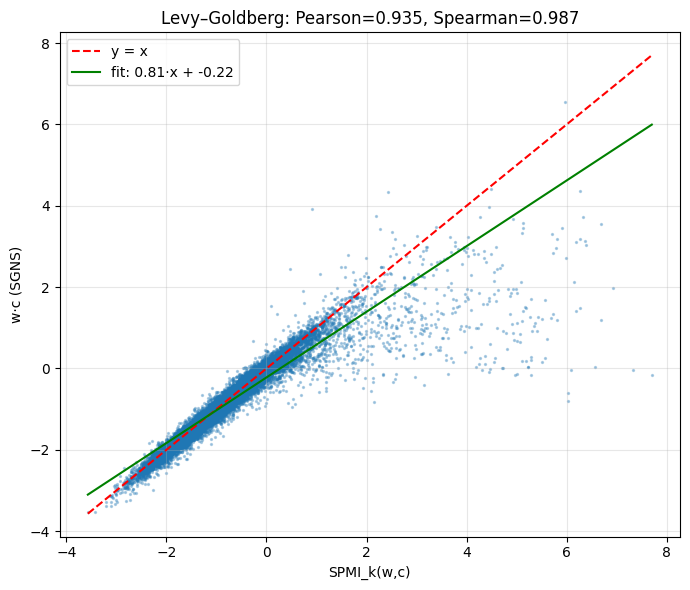

In [ ]:
import numpy as np
from scipy.stats import pearsonr, spearmanr

def check_levy_goldberg(W, C, cooc, k=K_NEG, min_count=50, alpha=0.75):
    W_np = W.detach().cpu().numpy().astype(np.float64)
    C_np = C.detach().cpu().numpy().astype(np.float64)

    cooc = cooc.tocsr().astype(np.float64)
    V = cooc.shape[0]

    # маргиналы из cooc
    row_sum = np.asarray(cooc.sum(axis=1)).ravel()
    col_sum = np.asarray(cooc.sum(axis=0)).ravel()

    # P_n(c) ∝ #(c)^0.75
    col_alpha = col_sum ** alpha
    total_alpha = col_alpha.sum()
    log_pn = alpha * np.log(col_sum) - np.log(total_alpha)

    # берём только частые пары
    coo = cooc.tocoo()
    mask = coo.data >= min_count
    rows = coo.row[mask]
    cols = coo.col[mask]
    counts_pairs = coo.data[mask]

    # w·c для этих пар
    wc = np.einsum("ij,ij->i", W_np[rows], C_np[cols])   # (n_pairs,)

    spmi = (np.log(counts_pairs)
            - np.log(row_sum[rows])
            - log_pn[cols]
            - np.log(k))

    # корреляции
    pearson_r,  _ = pearsonr(wc, spmi)
    spearman_r, _ = spearmanr(wc, spmi)
    mean_dev = np.mean(np.abs(wc - spmi))
    mean_signed = np.mean(wc - spmi)

    # линейная регрессия wc ≈ a * spmi + b
    A = np.vstack([spmi, np.ones_like(spmi)]).T
    (slope, intercept), *_ = np.linalg.lstsq(A, wc, rcond=None)

    print(f"пар с #(w,c) >= {min_count}: {len(wc):,}")
    print(f"Pearson  r = {pearson_r:.4f}")
    print(f"Spearman ρ = {spearman_r:.4f}")
    print(f"среднее |w·c − SPMI| = {mean_dev:.4f}")
    print(f"среднее (w·c − SPMI) = {mean_signed:.4f}")
    print(f"регрессия: w·c ≈ {slope:.4f} · SPMI + {intercept:.4f}")

    # scatter
    plt.figure(figsize=(7, 6))
    plt.scatter(spmi, wc, s=2, alpha=0.3)
    lo, hi = min(spmi.min(), wc.min()), max(spmi.max(), wc.max())
    plt.plot([lo, hi], [lo, hi], "r--", label="y = x")
    xs = np.linspace(spmi.min(), spmi.max(), 100)
    plt.plot(xs, slope * xs + intercept, "g-", label=f"fit: {slope:.2f}·x + {intercept:.2f}")
    plt.xlabel("SPMI_k(w,c)")
    plt.ylabel("w·c (SGNS)")
    plt.title(f"Levy–Goldberg: Pearson={pearson_r:.3f}, Spearman={spearman_r:.3f}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {"pearson": pearson_r, "spearman": spearman_r,
            "mean_abs_dev": mean_dev, "mean_signed_dev": mean_signed,
            "slope": slope, "intercept": intercept, "n_pairs": len(wc)}

res = check_levy_goldberg(W_sgns, C_sgns, cooc, k=K_NEG, min_count=50)

Выводы:

На 22 928 частых парах Pearson = 0.935, Spearman = 0.987 — теорема подтверждается. Регрессия ≈ 0.807·SPMI - 0.220: slope < 1 объясняется недообученностью (2 эпохи) и конечной размерностью d=100 << V=10 000.

## 7. Анизотропия

1. Посчитайте средний косинус между случайными парами слов для каждой модели.
2. Найдите долю дисперсии, объясняемую первыми 5 главными компонентами.
3. Примените «all-but-the-top» (Mu & Viswanath, 2018): вычесть среднее и проекции на первые \(D\) главных компонент. Как меняется качество на SimLex и MEN?

In [ ]:
def anisotropy(E, n=20000):
    En = normed(E)
    i, j = torch.randint(len(E), (n,)), torch.randint(len(E), (n,))
    return (En[i] * En[j]).sum(1).mean().item()

def all_but_the_top(E, D=3):
    X = E - E.mean(0, keepdim=True)
    if D == 0:
        return X
    U, S, Vt = torch.linalg.svd(X, full_matrices=False)
    V_D = Vt[:D]
    proj = (X @ V_D.T) @ V_D
    return X - proj

for name, E in [("SGNS (W)", W_sgns), ("SVD(PPMI)", W_svd)]:
    X = E - E.mean(0); s = torch.linalg.svdvals(X) ** 2
    print(f"{name:10s} средний cos={anisotropy(E):.3f}  доля 5 ГК={(s[:5].sum() / s.sum()).item():.3f}")
    for D in (0, 1, 3, 7):
        E2 = all_but_the_top(E, D) if D else E - E.mean(0)
        print(f"   D={D}: SimLex={eval_similarity(E2, sim_sets['simlex999'])[0]:.3f}  MEN={eval_similarity(E2, sim_sets['men'])[0]:.3f}  cos={anisotropy(E2):.3f}")

SGNS (W)   средний cos=0.675  доля 5 ГК=0.601
   D=0: SimLex=0.110  MEN=0.434  cos=0.006
   D=1: SimLex=0.043  MEN=0.430  cos=0.007
   D=3: SimLex=0.043  MEN=0.420  cos=0.005
   D=7: SimLex=0.054  MEN=0.296  cos=0.006
SVD(PPMI)  средний cos=0.073  доля 5 ГК=0.110
   D=0: SimLex=0.063  MEN=0.634  cos=0.003
   D=1: SimLex=0.053  MEN=0.631  cos=0.001
   D=3: SimLex=0.055  MEN=0.626  cos=0.001
   D=7: SimLex=0.056  MEN=0.619  cos=0.001


Выводы:

SGNS сильно анизотропен: средний косинус случайных пар 0.675, первые 5 ГК объясняют 60% дисперсии.

SVD(PPMI) почти изотропен (cos 0.073, 5 ГК 11%).

Центрирование убирает анизотропию (cos → 0.006), но на text8 метрики меняются разнонаправленно: MEN(SGNS) растёт 0.32 → 0.43, SimLex падает 0.115 → 0.110.

Удаление 1–3 главных компонент не улучшает метрики - на малом корпусе главные компоненты содержат полезный сигнал, а не только шум.

## Вопросы

1. Выведите оптимум \(\mathbf{w}^\top\mathbf{c}\) для SGNS из условия равенства нулю производной ожидаемой функции потерь по \(x = \mathbf{w}^\top\mathbf{c}\).
2. Почему отрицательные значения PMI отбрасывают (PPMI)? Что в SGNS соответствует этому усечению?
3. Почему сглаживание \(P_n(c) \propto \#(c)^{0.75}\) полезно и в SGNS, и в PPMI?
4. Чем объясняется анизотропия пространства эмбеддингов? Как она связана с частотой слов?
5. Почему SimLex-999 сложнее для дистрибутивных моделей, чем MEN?